# Week 1 run: Project #11 (Hybrid transfer learning)
Runtime -> Change runtime type -> **T4 GPU** (speeds up feature extraction only). Run cells top to bottom.

In [1]:
# 1. Get the code. Replace with your repository URL.
!git clone https://github.com/aliarslan007/QML_Hybrid_Transfer_Learning_For_Medical_Images.git repo
%cd repo

Cloning into 'repo'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (33/33), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 33 (delta 1), reused 33 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (33/33), 161.53 KiB | 7.69 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/repo


In [2]:
# 2. Install (torch/torchvision are preinstalled on Colab)
!pip install -q pennylane medmnist pyyaml

In [3]:
!python -m pytest -q

.......                                                                  [100%]
7 passed in 9.29s


In [4]:
# 3. Features (~2 min on GPU)
!python scripts/01_extract_features.py

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 175MB/s]
100% 214M/214M [00:41<00:00, 5.11MB/s]
train: X (4708, 512), positives 3494/4708
val  : X (524, 512), positives 389/524
test : X (624, 512), positives 390/624
Saved features to /content/repo/features/pneumoniamnist_224_resnet18.npz


In [5]:
# 4. Fixed folds
!python scripts/02_make_folds.py

Training pool: 4708 images, pneumonia fraction 0.742
n=   50: 5 folds, pneumonia fraction 0.740-0.740
n=  100: 5 folds, pneumonia fraction 0.740-0.740
n=  250: 5 folds, pneumonia fraction 0.744-0.744
n=  500: 5 folds, pneumonia fraction 0.742-0.742
n= 1000: 5 folds, pneumonia fraction 0.742-0.742
Saved to /content/repo/folds/pneumoniamnist_folds.json


In [6]:
# 5. Gradient check: must print PASS twice
!python scripts/05_gradient_check.py

d=4: 26 parameters, max |backprop - parameter-shift| = 1.91e-17 -> PASS
d=8: 50 parameters, max |backprop - parameter-shift| = 2.78e-17 -> PASS


In [7]:
# 6. Classical baselines (full grid)
!python scripts/03_run_classical.py

PCA d=4: explained variance 0.420
PCA d=8: explained variance 0.536
[ref512] n=50 fold=0 test AUROC=0.915
[ref512] n=50 fold=1 test AUROC=0.949
[ref512] n=50 fold=2 test AUROC=0.936
[ref512] n=50 fold=3 test AUROC=0.938
[ref512] n=50 fold=4 test AUROC=0.927
[ref512] n=100 fold=0 test AUROC=0.957
[ref512] n=100 fold=1 test AUROC=0.951
[ref512] n=100 fold=2 test AUROC=0.964
[ref512] n=100 fold=3 test AUROC=0.942
[ref512] n=100 fold=4 test AUROC=0.929
[ref512] n=250 fold=0 test AUROC=0.941
[ref512] n=250 fold=1 test AUROC=0.963
[ref512] n=250 fold=2 test AUROC=0.965
[ref512] n=250 fold=3 test AUROC=0.973
[ref512] n=250 fold=4 test AUROC=0.965
[ref512] n=500 fold=0 test AUROC=0.961
[ref512] n=500 fold=1 test AUROC=0.973
[ref512] n=500 fold=2 test AUROC=0.966
[ref512] n=500 fold=3 test AUROC=0.966
[ref512] n=500 fold=4 test AUROC=0.979
[ref512] n=1000 fold=0 test AUROC=0.976
[ref512] n=1000 fold=1 test AUROC=0.969
[ref512] n=1000 fold=2 test AUROC=0.977
[ref512] n=1000 fold=3 test AUROC=0.9

In [8]:
# 7. First quantum model: VQC pilot (d=4, all n, fold 0, seed 0)
!python scripts/04_run_vqc.py

0: ──RY(0.00)──RY(0.08)───RZ(-0.16)──RY(0.01)──╭●───────╭X──RY(-0.04)──RZ(-0.17)──RY(-0.11)─╭● ···
1: ──RY(0.00)──RY(-0.02)──RZ(-0.10)──RY(-0.03)─╰X─╭●────│───RY(-0.04)──RZ(-0.04)──RY(0.04)──╰X ···
2: ──RY(0.00)──RY(0.07)───RZ(-0.11)──RY(-0.04)────╰X─╭●─│───RY(-0.17)──RZ(0.01)───RY(-0.16)─── ···
3: ──RY(0.00)──RY(0.08)───RZ(-0.03)──RY(-0.07)───────╰X─╰●──RY(-0.14)──RZ(-0.10)──RY(-0.02)─── ···

0: ··· ───────╭X─┤  <Z>
1: ··· ─╭●────│──┤  <Z>
2: ··· ─╰X─╭●─│──┤  <Z>
3: ··· ────╰X─╰●─┤  <Z>
[vqc] d=4 n=50 fold=0 seed=0 params=26 val=0.948 test AUROC=0.913 (10.82s)
[vqc] d=4 n=100 fold=0 seed=0 params=26 val=0.969 test AUROC=0.915 (10.71s)
[vqc] d=4 n=250 fold=0 seed=0 params=26 val=0.957 test AUROC=0.902 (12.11s)
[vqc] d=4 n=500 fold=0 seed=0 params=26 val=0.968 test AUROC=0.909 (13.16s)
[vqc] d=4 n=1000 fold=0 seed=0 params=26 val=0.972 test AUROC=0.921 (16.1s)


                            mean     std  count
head            d   n                          
linear          4   50    0.8905  0.0222     15
                    100   0.9075  0.0113     15
                    250   0.9086  0.0099     15
                    500   0.9134  0.0039     15
                    1000  0.9140  0.0010     15
                8   50    0.8794  0.0498     15
                    100   0.8910  0.0428     15
                    250   0.9218  0.0145     15
                    500   0.9268  0.0057     15
                    1000  0.9317  0.0056     15
lr512_reference 512 50    0.9329  0.0128      5
                    100   0.9485  0.0134      5
                    250   0.9613  0.0119      5
                    500   0.9690  0.0072      5
                    1000  0.9717  0.0043      5
mlp             4   50    0.8776  0.0337     15
                    100   0.8918  0.0265     15
                    250   0.9097  0.0124     15
                    500   0.9148  0.0050

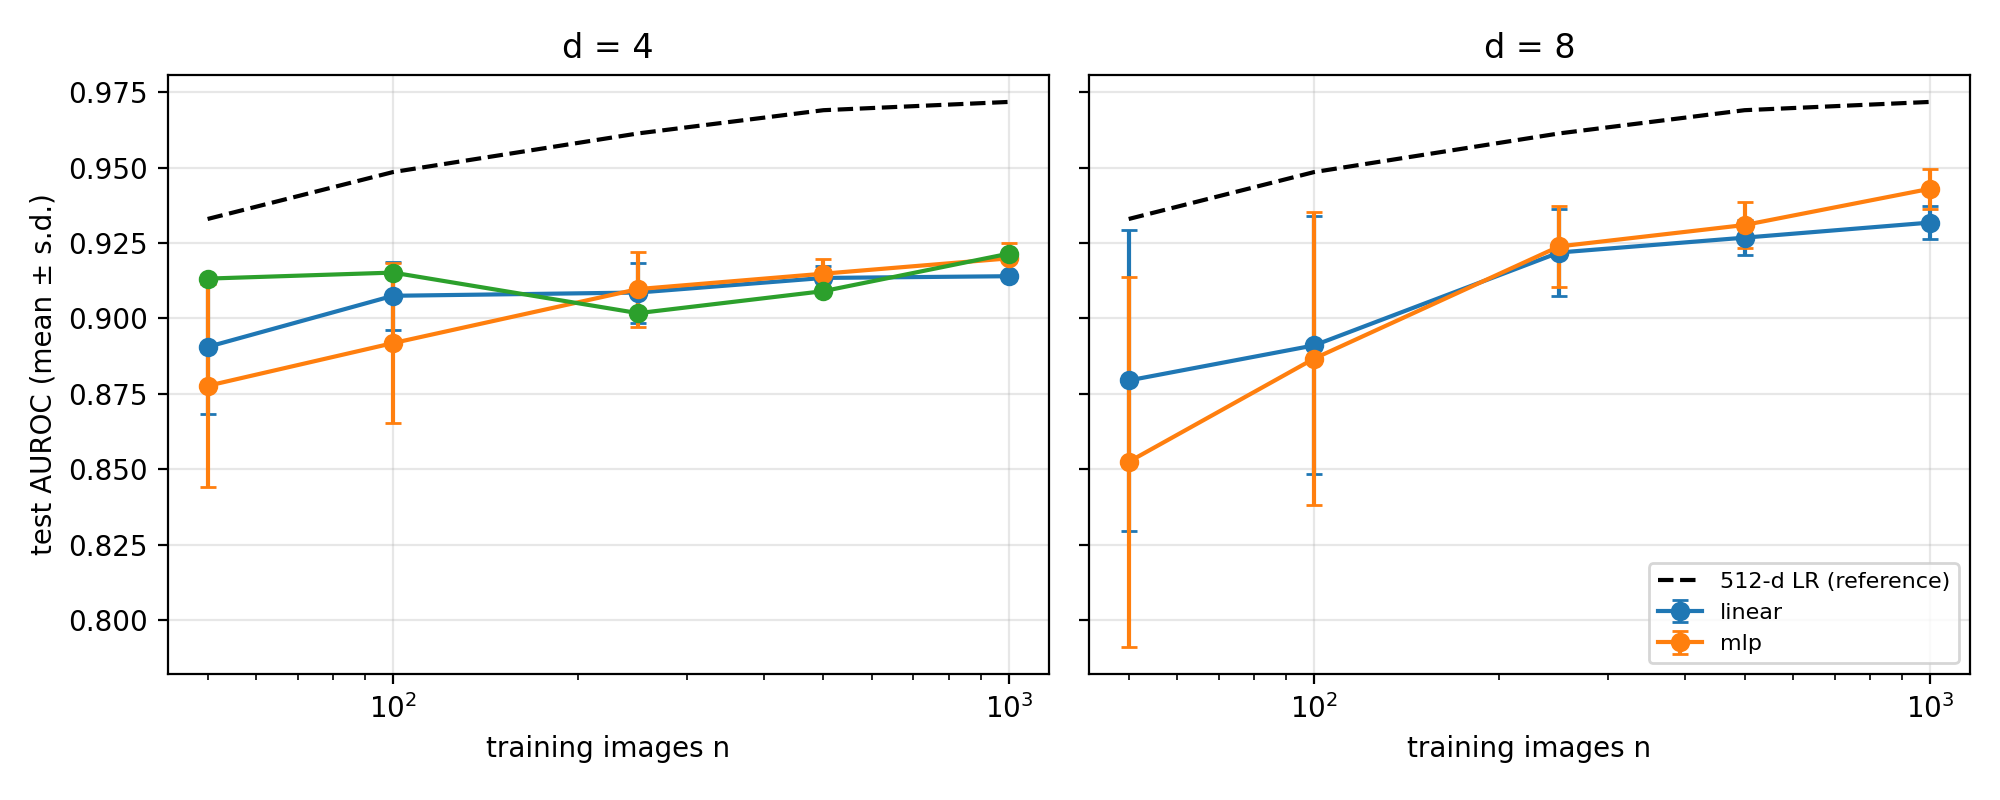

In [9]:
# 8. Summary + learning curves
!python scripts/06_summarize.py
from IPython.display import Image
Image('results/learning_curves.png')

In [10]:
# 9. Download folds + results to commit to GitHub
!zip -r week1_outputs.zip folds results
from google.colab import files
files.download('week1_outputs.zip')

  adding: folds/ (stored 0%)
  adding: folds/pneumoniamnist_folds.json (deflated 81%)
  adding: folds/.gitkeep (stored 0%)
  adding: results/ (stored 0%)
  adding: results/vqc.csv (deflated 57%)
  adding: results/classical.csv (deflated 71%)
  adding: results/learning_curves.png (deflated 11%)
  adding: results/.gitkeep (stored 0%)
  adding: results/summary.csv (deflated 68%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>